In [1]:
import polars as pl
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np

In [2]:
df = pl.read_excel("profile_coeffs_ref.xlsx")

In [3]:
filtered_df = df.filter(
    ~(
        pl.col("Source").str.contains("Acid") | 
        pl.col("Source").str.contains("FAME") | 
        pl.col("Source").str.contains("MAG/DAG")
    )
)

In [4]:
stats_df = filtered_df.group_by('Source').agg([
    # For column 'm'
    pl.col('m').min().alias('m_min'),
    pl.col('m').quantile(0.25).alias('m_q25'),
    pl.col('m').median().alias('m_median'),
    pl.col('m').quantile(0.75).alias('m_q75'),
    pl.col('m').max().alias('m_max'),
    pl.col('m').mean().alias('m_mean'),
    
    # For column 'n'
    pl.col('n').min().alias('n_min'),
    pl.col('n').quantile(0.25).alias('n_q25'),
    pl.col('n').median().alias('n_median'),
    pl.col('n').quantile(0.75).alias('n_q75'),
    pl.col('n').max().alias('n_max'),
    pl.col('n').mean().alias('n_mean'),
    
    # For column 'p'
    pl.col('p').min().alias('p_min'),
    pl.col('p').quantile(0.25).alias('p_q25'),
    pl.col('p').median().alias('p_median'),
    pl.col('p').quantile(0.75).alias('p_q75'),
    pl.col('p').max().alias('p_max'),
    pl.col('p').mean().alias('p_mean'),
    
])

with pl.Config(tbl_rows=len(stats_df), tbl_cols=-1):
    print(stats_df)

shape: (40, 19)
┌─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┐
│ Sou ┆ m_m ┆ m_q ┆ m_m ┆ m_q ┆ m_m ┆ m_m ┆ n_m ┆ n_q ┆ n_m ┆ n_q ┆ n_m ┆ n_m ┆ p_m ┆ p_q ┆ p_m ┆ p_q ┆ p_m ┆ p_m │
│ rce ┆ in  ┆ 25  ┆ edi ┆ 75  ┆ ax  ┆ ean ┆ in  ┆ 25  ┆ edi ┆ 75  ┆ ax  ┆ ean ┆ in  ┆ 25  ┆ edi ┆ 75  ┆ ax  ┆ ean │
│ --- ┆ --- ┆ --- ┆ an  ┆ --- ┆ --- ┆ --- ┆ --- ┆ --- ┆ an  ┆ --- ┆ --- ┆ --- ┆ --- ┆ --- ┆ an  ┆ --- ┆ --- ┆ --- │
│ str ┆ f64 ┆ f64 ┆ --- ┆ f64 ┆ f64 ┆ f64 ┆ f64 ┆ f64 ┆ --- ┆ f64 ┆ f64 ┆ f64 ┆ f64 ┆ f64 ┆ --- ┆ f64 ┆ f64 ┆ f64 │
│     ┆     ┆     ┆ f64 ┆     ┆     ┆     ┆     ┆     ┆ f64 ┆     ┆     ┆     ┆     ┆     ┆ f64 ┆     ┆     ┆     │
╞═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╡
│ Mac ┆ 13. ┆ 13. ┆ 13. ┆ 13. ┆ 13. ┆ 13. ┆ 0.8 ┆ 0.8 ┆ 0.8 ┆ 0.9 ┆ 0.9 ┆ 0.8 ┆ 0.0 ┆ 0.0 ┆ 0.0 ┆ 0.0 ┆ 0.0 ┆ 0.0 │
│ aub ┆ 674 ┆ 674 ┆ 701 ┆ 728 ┆ 728 ┆ 701 ┆ 668 ┆ 668 ┆ 

In [5]:
count_values = filtered_df.group_by('Source').agg(
    pl.col('m').count().alias('m_count')
)

count_values = count_values.sort(by="m_count", descending=True)

with pl.Config(tbl_rows=len(count_values)):
    print(count_values)

shape: (40, 2)
┌─────────────────────────────┬─────────┐
│ Source                      ┆ m_count │
│ ---                         ┆ ---     │
│ str                         ┆ u32     │
╞═════════════════════════════╪═════════╡
│ Soybean                     ┆ 13      │
│ Sunflower                   ┆ 7       │
│ Cottonseed                  ┆ 5       │
│ Castor                      ┆ 4       │
│ Corn                        ┆ 4       │
│ Rice Bran                   ┆ 3       │
│ Canola                      ┆ 3       │
│ Canola                      ┆ 3       │
│ Oleic                       ┆ 2       │
│ Jatropha                    ┆ 2       │
│ Brazil Nut                  ┆ 2       │
│ Peanut                      ┆ 2       │
│ Macauba                     ┆ 2       │
│ Babassu                     ┆ 2       │
│ Palm                        ┆ 2       │
│ Crambe                      ┆ 2       │
│ Coconut                     ┆ 2       │
│ Fodder Radish               ┆ 1       │
│ Grape Seed       

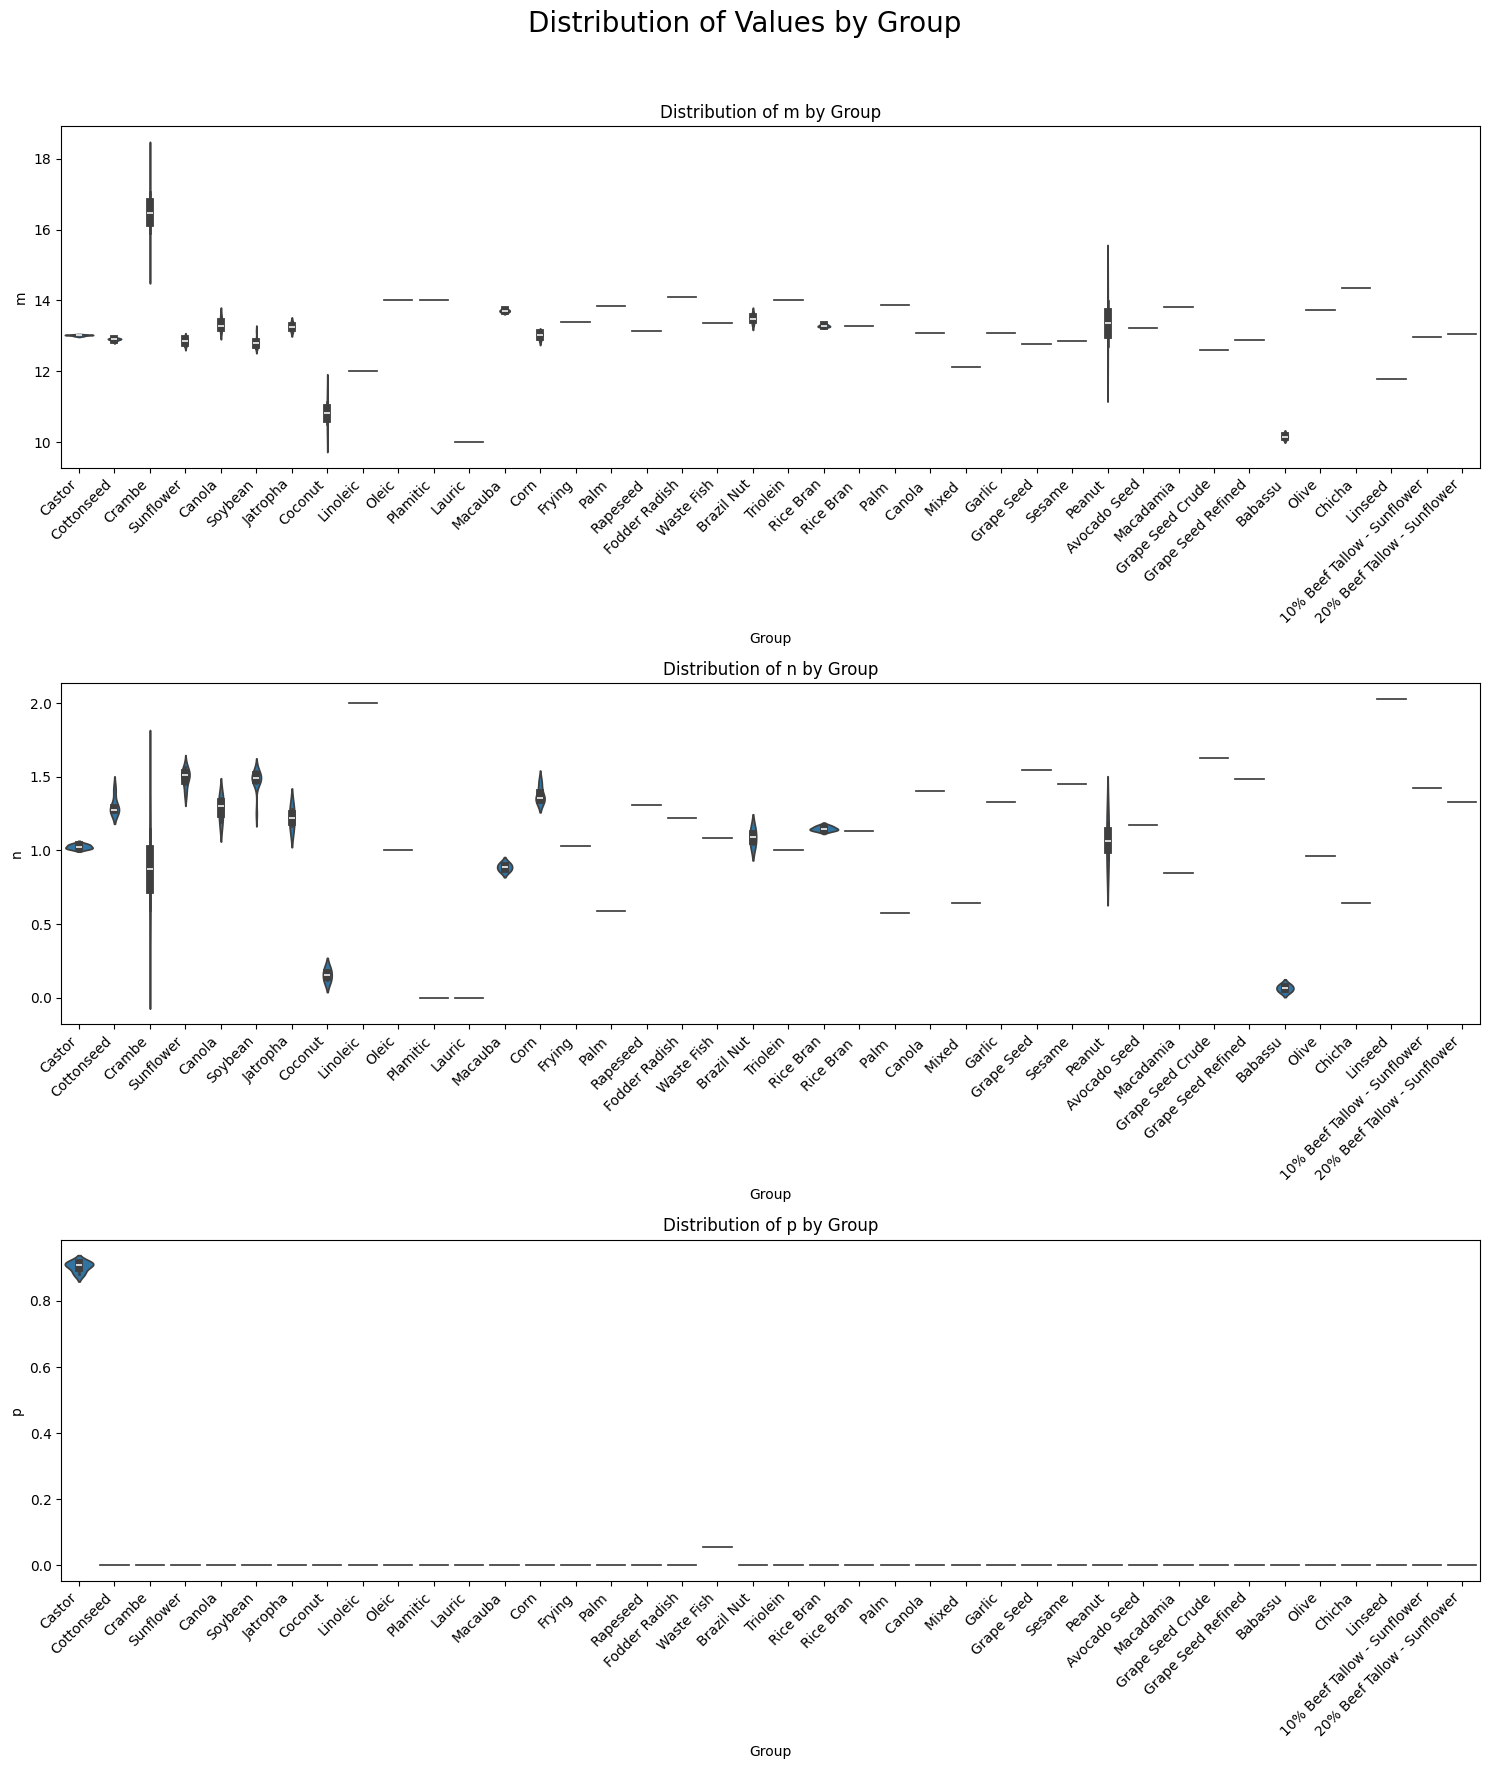

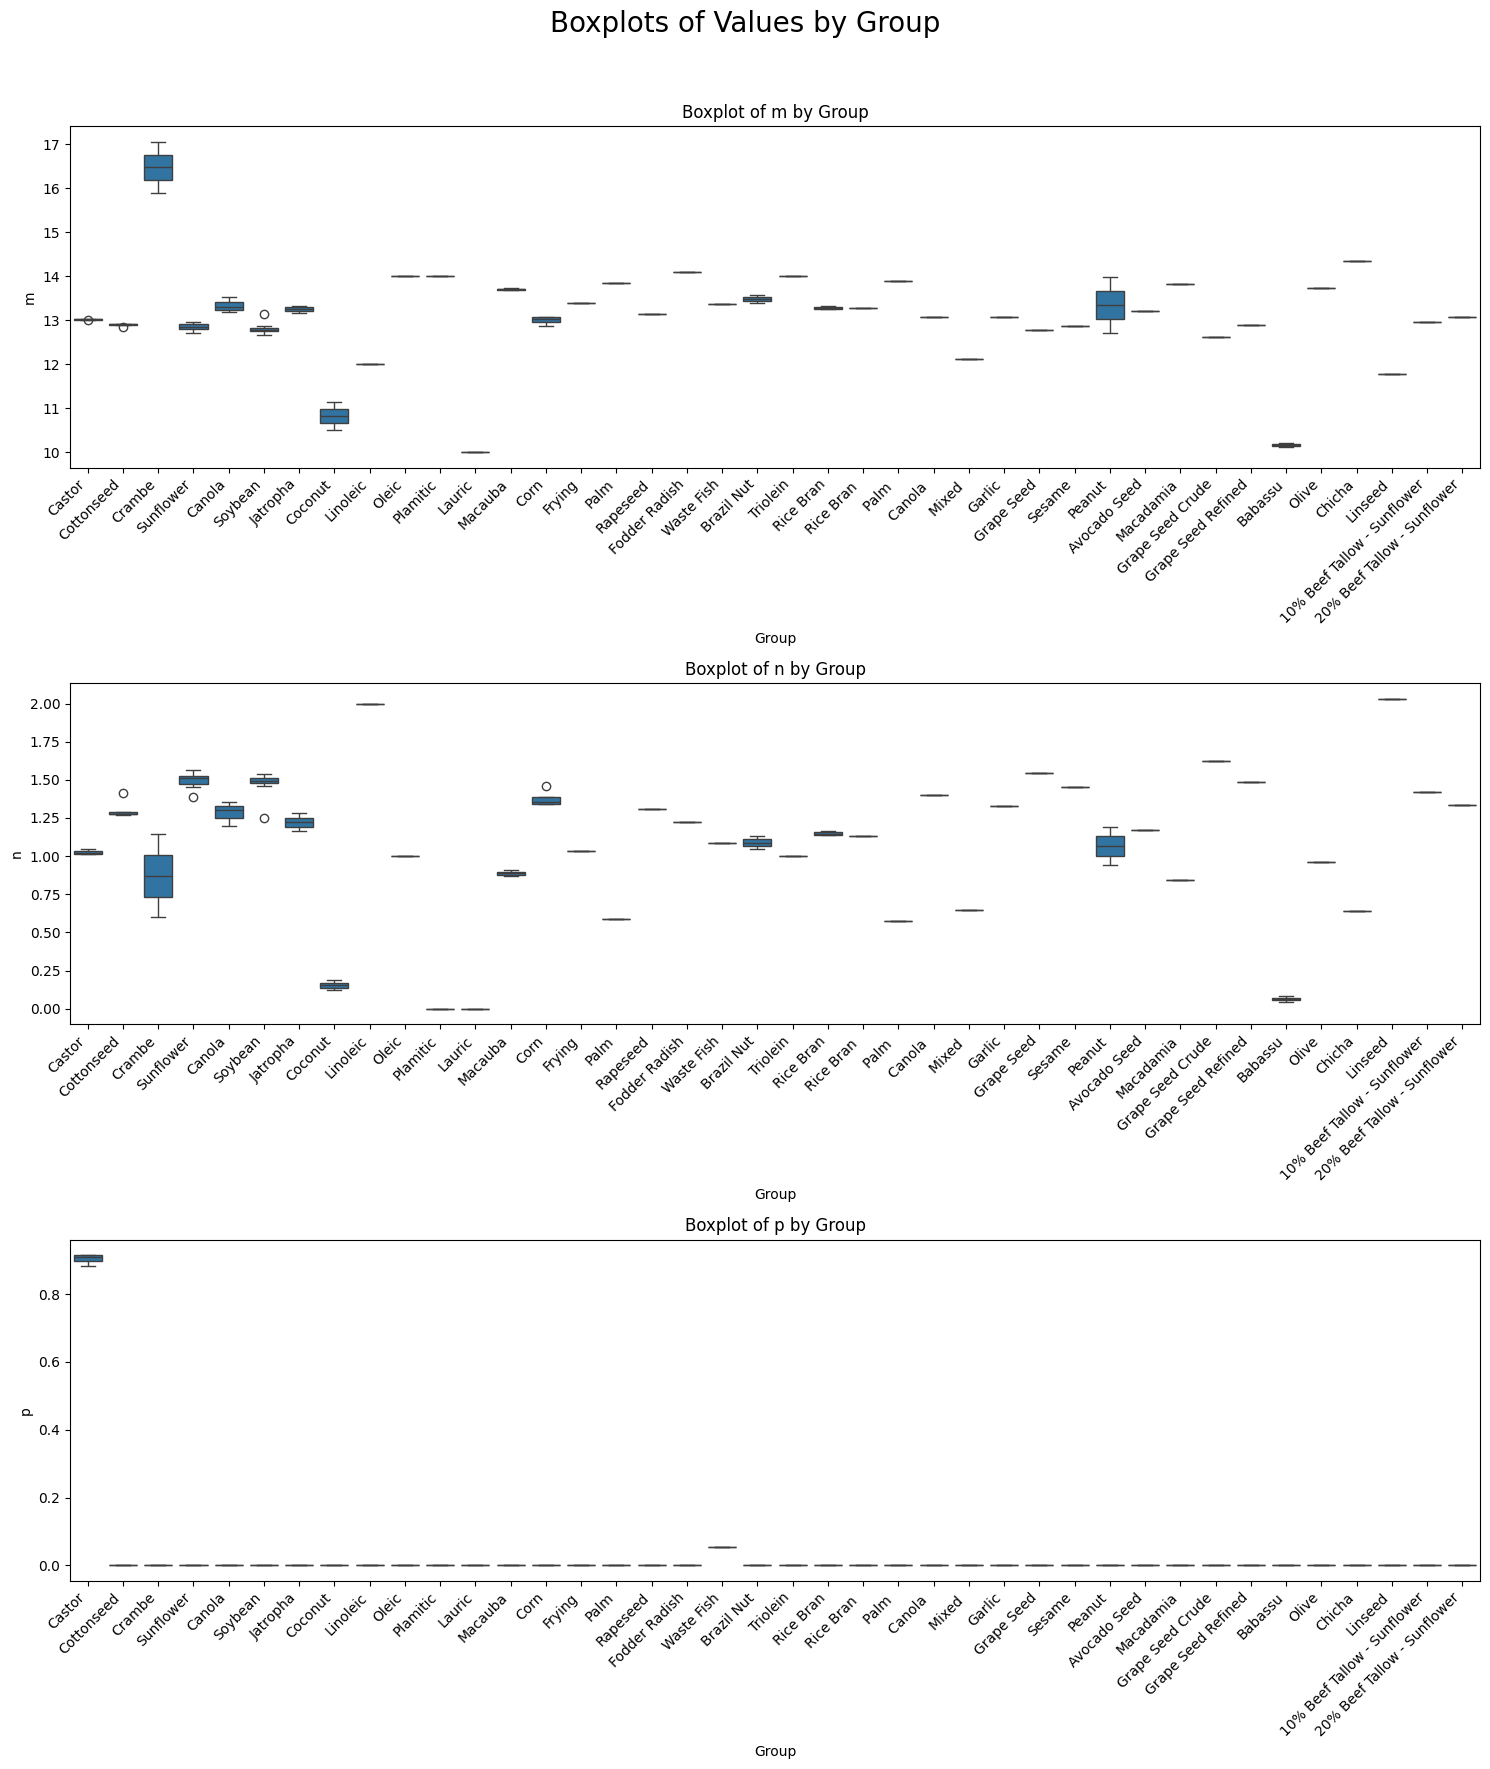

In [6]:
df_pandas = filtered_df.to_pandas()

# Set up the figure
fig, axes = plt.subplots(3, 1, figsize=(15, 18))
fig.suptitle('Distribution of Values by Group', fontsize=20)

# Flatten the axes array for easier iteration
axes = axes.flatten()

# Columns to plot
columns = ['m', 'n', 'p']

# Create distribution plots
for i, col in enumerate(columns):
    # Using seaborn's violinplot for distribution visualization
    sns.violinplot(x='Source', y=col, data=df_pandas, ax=axes[i])
    axes[i].set_title(f'Distribution of {col} by Group')
    axes[i].set_xlabel('Group')
    axes[i].set_ylabel(col)
    
    # Rotate x-axis labels if there are many groups
    plt.setp(axes[i].get_xticklabels(), rotation=45, ha='right')

# Adjust layout
plt.tight_layout(rect=[0, 0, 1, 0.96])  # Make room for the title
plt.show()

# Alternatively, you can create boxplots which might be clearer
# for comparing distributions between groups
fig, axes = plt.subplots(3, 1, figsize=(15, 18))
fig.suptitle('Boxplots of Values by Group', fontsize=20)

axes = axes.flatten()

for i, col in enumerate(columns):
    sns.boxplot(x='Source', y=col, data=df_pandas, ax=axes[i])
    axes[i].set_title(f'Boxplot of {col} by Group')
    axes[i].set_xlabel('Group')
    axes[i].set_ylabel(col)
    
    # Rotate x-axis labels if there are many groups
    plt.setp(axes[i].get_xticklabels(), rotation=45, ha='right')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [7]:
group_stats_dfs = {}

# List of statistics in desired order
stats_order = ['min', 'q25', 'median', 'q75', 'max', 'mean']

# For each group in the stats_df
for group_row in stats_df.iter_rows(named=True):
    group_name = group_row['Source']
    
    # Create a DataFrame for this group
    # Initialize with stat names as the first column
    group_data = {'stat': stats_order}
    
    # Add each column's statistics
    for col in ['m', 'n', 'p']:
        # Extract values for each statistic for this column
        col_values = [
            group_row[f'{col}_min'],   # min
            group_row[f'{col}_q25'],   # q25 
            group_row[f'{col}_median'], # median
            group_row[f'{col}_q75'],   # q75
            group_row[f'{col}_max'],   # max
            group_row[f'{col}_mean']   # mean
        ]
        
        # Add to the group data dictionary
        group_data[col] = col_values
    
    # Create a DataFrame for this group
    group_stats_dfs[group_name] = pl.DataFrame(group_data)

# Now we have a dictionary where each key is a group name
# and the value is a DataFrame with 6 rows (statistics) and 5 columns 
# (stat name, m, n, p, b)

# Print each group's DataFrame
for group_name, df in group_stats_dfs.items():
    print(f"\nStatistics for group: {group_name}")
    print(df)

# If you want to export these to CSV files
for group_name, df in group_stats_dfs.items():
    # Create a safe filename (replace spaces and special characters)
    safe_name = ''.join(c if c.isalnum() else '_' for c in str(group_name))


Statistics for group: Macauba
shape: (6, 4)
┌────────┬───────────┬──────────┬─────┐
│ stat   ┆ m         ┆ n        ┆ p   │
│ ---    ┆ ---       ┆ ---      ┆ --- │
│ str    ┆ f64       ┆ f64      ┆ f64 │
╞════════╪═══════════╪══════════╪═════╡
│ min    ┆ 13.674442 ┆ 0.866834 ┆ 0.0 │
│ q25    ┆ 13.674442 ┆ 0.866834 ┆ 0.0 │
│ median ┆ 13.701642 ┆ 0.886618 ┆ 0.0 │
│ q75    ┆ 13.728841 ┆ 0.906403 ┆ 0.0 │
│ max    ┆ 13.728841 ┆ 0.906403 ┆ 0.0 │
│ mean   ┆ 13.701642 ┆ 0.886618 ┆ 0.0 │
└────────┴───────────┴──────────┴─────┘

Statistics for group: Macadamia
shape: (6, 4)
┌────────┬───────────┬──────────┬─────┐
│ stat   ┆ m         ┆ n        ┆ p   │
│ ---    ┆ ---       ┆ ---      ┆ --- │
│ str    ┆ f64       ┆ f64      ┆ f64 │
╞════════╪═══════════╪══════════╪═════╡
│ min    ┆ 13.821388 ┆ 0.846005 ┆ 0.0 │
│ q25    ┆ 13.821388 ┆ 0.846005 ┆ 0.0 │
│ median ┆ 13.821388 ┆ 0.846005 ┆ 0.0 │
│ q75    ┆ 13.821388 ┆ 0.846005 ┆ 0.0 │
│ max    ┆ 13.821388 ┆ 0.846005 ┆ 0.0 │
│ mean   ┆ 13.821388 ┆ 0.846

In [8]:
# Assuming we already have 'group_stats_dfs' dictionary from previous code
# where keys are group names and values are the condensed DataFrames

# Create an empty list to store all group DataFrames with added group column
all_group_dfs = []

# Process each group DataFrame
for group_name, df in group_stats_dfs.items():
    # Add a 'group' column with the group name
    df_with_group = df.with_columns(pl.lit(group_name).alias('group'))
    
    # Reorder columns to put group first
    df_with_group = df_with_group.select(['group', 'stat', 'm', 'n', 'p'])
    
    # Add to our list
    all_group_dfs.append(df_with_group)

# Concatenate all DataFrames into a single DataFrame
combined_stats_df = pl.concat(all_group_dfs)

# Sort by group name and then by stat (to keep stats in their logical order)
# We'll create a custom sort order for stats to maintain the original order
stat_order = {
    'min': 1, 
    'q25': 2, 
    'median': 3, 
    'q75': 4, 
    'max': 5, 
    'mean': 6
}

# Function to determine sort order for combined stats (like 'min/max')
def get_stat_sort_value(stat_name):
    if '/' in stat_name:
        # For combined stats, use the first mentioned stat for sorting
        first_stat = stat_name.split('/')[0]
        return stat_order.get(first_stat, 99)
    else:
        return stat_order.get(stat_name, 99)

# Create a sorted version with custom stat ordering
sorted_stats_df = combined_stats_df.sort(
    by=['group', 
        pl.col('stat').map_elements(lambda x: get_stat_sort_value(x), return_dtype=float)
    ]
)

# Display the combined DataFrame
print("Combined statistics for all groups:")
with pl.Config(tbl_rows=len(sorted_stats_df)):
    print(sorted_stats_df)

Combined statistics for all groups:
shape: (240, 5)
┌─────────────────────────────┬────────┬───────────┬──────────┬──────────┐
│ group                       ┆ stat   ┆ m         ┆ n        ┆ p        │
│ ---                         ┆ ---    ┆ ---       ┆ ---      ┆ ---      │
│ str                         ┆ str    ┆ f64       ┆ f64      ┆ f64      │
╞═════════════════════════════╪════════╪═══════════╪══════════╪══════════╡
│ 10% Beef Tallow - Sunflower ┆ min    ┆ 12.95354  ┆ 1.422083 ┆ 0.0      │
│ 10% Beef Tallow - Sunflower ┆ q25    ┆ 12.95354  ┆ 1.422083 ┆ 0.0      │
│ 10% Beef Tallow - Sunflower ┆ median ┆ 12.95354  ┆ 1.422083 ┆ 0.0      │
│ 10% Beef Tallow - Sunflower ┆ q75    ┆ 12.95354  ┆ 1.422083 ┆ 0.0      │
│ 10% Beef Tallow - Sunflower ┆ max    ┆ 12.95354  ┆ 1.422083 ┆ 0.0      │
│ 10% Beef Tallow - Sunflower ┆ mean   ┆ 12.95354  ┆ 1.422083 ┆ 0.0      │
│ 20% Beef Tallow - Sunflower ┆ min    ┆ 13.062795 ┆ 1.333019 ┆ 0.0      │
│ 20% Beef Tallow - Sunflower ┆ q25    ┆ 13.0627

In [9]:
processed_df =  combined_stats_df.with_columns(
    pl.lit(2).alias('b')
)

In [ ]:
processed_df
#processed_df.write_csv("sensitivity_params_pro.csv")

In [77]:
processed_df = pl.read_csv("sensitivity_params.csv")

In [11]:
MW_df = processed_df.with_columns(
         (15*2 + 14*pl.col("m") + 26*pl.col("n") + 30*pl.col("p") + 58 + 14*pl.col("b")).alias("MW_FAME/FAEE"),
         pl.lit(92.09).alias("MW_Glycerol"),
         pl.when(pl.col("b") == 0).then(32.04).when(pl.col("b") == 1).then(46.07).when(pl.col("b") == 2).then(60.09).otherwise(None).alias("MW_Alcohol"),
         (15*3 + 14*(3*pl.col("m")+2) + 26*3*pl.col("n") + 13*(3*pl.col("p")+1) + 17*3*pl.col("p") + 58*3).alias("MW_Oil"),
         (15*2 + 14*(2*pl.col("m")+2) + 26*2*pl.col("n") + 13*(2*pl.col("p")+1) + 17*2*pl.col("p") + 58*2).alias("MW_DAG"),
         (15 + 14*(pl.col("m")+2) + 26*pl.col("n") + 13*(pl.col("p")+1) + 17*pl.col("p") + 58).alias("MW_MAG"),
         (15 + 14*pl.col("m") + 26*pl.col("n") + 30*pl.col("p") + 45).alias("MW_FA"),
         pl.lit(18).alias("MW_H2O") 
      )



In [ ]:
MW_df = MW_df.drop(["m", "n", "p", "b"])
#MW_df.write_csv("sensitivity_MW_pro.csv")

In [13]:
coeffs_groups  = processed_df.group_by(["group", "stat"])

In [14]:
v_total = []
for name, data in coeffs_groups:
    data = data.drop(["group", "stat"]).to_numpy()
    
    v = np.array([
            [data[0][2],     1.0,    0,                   3*data[0][2] + 1,         2*data[0][2] + 1,     data[0][2] + 1, data[0][2],  0],
            [data[0][0],     2.0,    data[0][3],          3*data[0][0] + 2,         2*data[0][0] + 2,     data[0][0] + 2, data[0][0] , 0],
            [2.0,            0,      1.0,                 3.0,                      2.0,                  1.0,            1.0,         0],
            [data[0][1],     0,      0,                   3*data[0][1],             2*data[0][1],         data[0][1],     data[0][1],  0],
            [data[0][2],     3.0,    1.0,                 3*data[0][2],             2*data[0][2],         data[0][2],     data[0][2],  0],
            [1.0,            0,      0,                   3.0,                      2.0,                  1.0,            0,           0],
            [0,              0,      0,                   0,                        0,                    0,              1.0,         0],
            [0,              0,      0,                   0,                        0,                    0,              0,         1.0]])
    
    
    df = pl.DataFrame(v, schema=["FAME/FAEE", "GLYCEROL", "ALCOHOL", "OIL", "DAG", "MAG", "ACID", "H2O"])
    
    df = df.with_columns(
        pl.lit(name[0]).alias('Group'), 
        pl.lit(name[1]).alias('Stat')
    )
    
    v_total.append(df)

In [15]:
v_total_df = pl.concat(v_total)

In [ ]:
#v_total_df.write_csv("sensitivity_group_contribution_pro.csv")

In [84]:
with pl.Config(tbl_rows=len(v_total_df)):
    print(v_total_df)

shape: (784, 10)
┌───────────┬──────────┬─────────┬───────────┬───┬───────────┬─────┬──────────────────────┬────────┐
│ FAME/FAEE ┆ GLYCEROL ┆ ALCOHOL ┆ OIL       ┆ … ┆ ACID      ┆ H2O ┆ Group                ┆ Stat   │
│ ---       ┆ ---      ┆ ---     ┆ ---       ┆   ┆ ---       ┆ --- ┆ ---                  ┆ ---    │
│ f64       ┆ f64      ┆ f64     ┆ f64       ┆   ┆ f64       ┆ f64 ┆ str                  ┆ str    │
╞═══════════╪══════════╪═════════╪═══════════╪═══╪═══════════╪═════╪══════════════════════╪════════╡
│ 0.0       ┆ 1.0      ┆ 0.0     ┆ 1.0       ┆ … ┆ 0.0       ┆ 0.0 ┆ Coconut              ┆ min    │
│ 10.499156 ┆ 2.0      ┆ 0.0     ┆ 33.497469 ┆ … ┆ 10.499156 ┆ 0.0 ┆ Coconut              ┆ min    │
│ 2.0       ┆ 0.0      ┆ 1.0     ┆ 3.0       ┆ … ┆ 1.0       ┆ 0.0 ┆ Coconut              ┆ min    │
│ 0.119954  ┆ 0.0      ┆ 0.0     ┆ 0.359862  ┆ … ┆ 0.119954  ┆ 0.0 ┆ Coconut              ┆ min    │
│ 0.0       ┆ 3.0      ┆ 1.0     ┆ 0.0       ┆ … ┆ 0.0       ┆ 0.0 ┆ Cocon